In [ ]:
# -------------------------------
# 0️⃣ Colab & Drive Setup
# -------------------------------
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
import timm
import numpy as np

# -------------------------------
# 1️⃣ Dataset + folds setup
# -------------------------------
from torchvision.datasets import ImageFolder
from torchvision import transforms
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report

data_dir = '/content/drive/MyDrive/Flood_data_k_fold/train'
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()
])
full_dataset = ImageFolder(data_dir, transform=transform)
labels = np.array(full_dataset.targets)
num_classes = len(full_dataset.classes)
class_names = full_dataset.classes   # ✅ save class names

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# -------------------------------
# 2️⃣ Device setup
# -------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------------
# 3️⃣ 5-Fold Training Loop
# -------------------------------
fold_results = []
train_acc_history = []
val_acc_history = []

for fold, (train_idx, val_idx) in enumerate(kf.split(np.zeros(len(labels)), labels)):
    print(f"\n🔹 Fold {fold+1}")

    # Subset loaders
    train_loader = DataLoader(Subset(full_dataset, train_idx), batch_size=32, shuffle=True)
    val_loader   = DataLoader(Subset(full_dataset, val_idx), batch_size=32, shuffle=False)

    # Model
    model = timm.create_model('vit_tiny_patch16_224', pretrained=True, num_classes=num_classes)
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=3e-5, weight_decay=0.01)

    best_val_acc_fold = 0
    best_train_acc_fold = 0
    fold_train_acc = []
    fold_val_acc = []
    epochs = 10

    # ---- Training + Validation ----
    for epoch in range(epochs):
        # Training
        model.train()
        correct, total = 0, 0
        for images, labels_batch in train_loader:
            images, labels_batch = images.to(device), labels_batch.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels_batch)
            loss.backward()
            optimizer.step()
            correct += (outputs.argmax(1) == labels_batch).sum().item()
            total += labels_batch.size(0)
        train_accuracy = correct / total
        fold_train_acc.append(train_accuracy)

        # Validation
        model.eval()
        correct, total = 0, 0
        all_preds, all_targets = [], []   # ✅ store predictions & labels
        with torch.no_grad():
            for images, labels_batch in val_loader:
                images, labels_batch = images.to(device), labels_batch.to(device)
                outputs = model(images)
                preds = outputs.argmax(1)
                all_preds.extend(preds.cpu().numpy())
                all_targets.extend(labels_batch.cpu().numpy())
                correct += (preds == labels_batch).sum().item()
                total += labels_batch.size(0)
        val_accuracy = correct / total
        fold_val_acc.append(val_accuracy)

        # Save best model for this fold
        if val_accuracy > best_val_acc_fold:
            best_val_acc_fold = val_accuracy
            best_train_acc_fold = train_accuracy   # ✅ Save corresponding train acc
            save_path = f'/content/drive/MyDrive/models/best_vit_fold{fold+1}.pth'
            torch.save(model.state_dict(), save_path)
            print(f"💾 Saved best model for Fold {fold+1} at Epoch {epoch+1}")

        print(f"Epoch {epoch+1}/{epochs} => Train Acc: {train_accuracy:.4f}, Val Acc: {val_accuracy:.4f}")

    # -------------------------------
    # ✅ Classification Report for this Fold
    # -------------------------------
    print(f"\n📑 Fold {fold+1} Results:")
    print(f"👉 Best Train Accuracy: {best_train_acc_fold:.4f}")
    print(f"👉 Best Validation Accuracy: {best_val_acc_fold:.4f}")
    print("👉 Classification Report:")
    print(classification_report(all_targets, all_preds, target_names=class_names, digits=4))

    fold_results.append(best_val_acc_fold)
    train_acc_history.append(fold_train_acc)
    val_acc_history.append(fold_val_acc)

print("\n📊 All Fold Best Validation Accuracies:", fold_results)
print(f"📌 Average Validation Accuracy: {np.mean(fold_results):.4f}")



🔹 Fold 1


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/22.9M [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


💾 Saved best model for Fold 1 at Epoch 1
Epoch 1/10 => Train Acc: 0.7143, Val Acc: 0.9136
💾 Saved best model for Fold 1 at Epoch 2
Epoch 2/10 => Train Acc: 0.9658, Val Acc: 0.9506
Epoch 3/10 => Train Acc: 0.9876, Val Acc: 0.9506
💾 Saved best model for Fold 1 at Epoch 4
Epoch 4/10 => Train Acc: 1.0000, Val Acc: 0.9630
Epoch 5/10 => Train Acc: 1.0000, Val Acc: 0.9630
Epoch 6/10 => Train Acc: 1.0000, Val Acc: 0.9630
Epoch 7/10 => Train Acc: 1.0000, Val Acc: 0.9630
Epoch 8/10 => Train Acc: 1.0000, Val Acc: 0.9630
Epoch 9/10 => Train Acc: 1.0000, Val Acc: 0.9630
Epoch 10/10 => Train Acc: 1.0000, Val Acc: 0.9630

📑 Fold 1 Results:
👉 Best Train Accuracy: 1.0000
👉 Best Validation Accuracy: 0.9630
👉 Classification Report:
              precision    recall  f1-score   support

    flooding     0.9333    1.0000    0.9655        42
      normal     1.0000    0.9231    0.9600        39

    accuracy                         0.9630        81
   macro avg     0.9667    0.9615    0.9628        81
weigh

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


... (3 outputs left out)

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


💾 Saved best model for Fold 4 at Epoch 1
Epoch 1/10 => Train Acc: 0.8050, Val Acc: 0.9625
Epoch 2/10 => Train Acc: 0.9876, Val Acc: 0.9625
Epoch 3/10 => Train Acc: 0.9969, Val Acc: 0.9625
💾 Saved best model for Fold 4 at Epoch 4
Epoch 4/10 => Train Acc: 1.0000, Val Acc: 0.9750
Epoch 5/10 => Train Acc: 1.0000, Val Acc: 0.9750
Epoch 6/10 => Train Acc: 1.0000, Val Acc: 0.9750
Epoch 7/10 => Train Acc: 1.0000, Val Acc: 0.9750
Epoch 8/10 => Train Acc: 1.0000, Val Acc: 0.9750
Epoch 9/10 => Train Acc: 1.0000, Val Acc: 0.9750
Epoch 10/10 => Train Acc: 1.0000, Val Acc: 0.9750

📑 Fold 4 Results:
👉 Best Train Accuracy: 1.0000
👉 Best Validation Accuracy: 0.9750
👉 Classification Report:
              precision    recall  f1-score   support

    flooding     0.9545    1.0000    0.9767        42
      normal     1.0000    0.9474    0.9730        38

    accuracy                         0.9750        80
   macro avg     0.9773    0.9737    0.9749        80
weighted avg     0.9761    0.9750    0.9750   

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


💾 Saved best model for Fold 5 at Epoch 1
Epoch 1/10 => Train Acc: 0.7554, Val Acc: 0.8625
💾 Saved best model for Fold 5 at Epoch 2
Epoch 2/10 => Train Acc: 0.9752, Val Acc: 0.9000
💾 Saved best model for Fold 5 at Epoch 3
Epoch 3/10 => Train Acc: 0.9907, Val Acc: 0.9375
Epoch 4/10 => Train Acc: 1.0000, Val Acc: 0.9375
💾 Saved best model for Fold 5 at Epoch 5
Epoch 5/10 => Train Acc: 1.0000, Val Acc: 0.9500
Epoch 6/10 => Train Acc: 1.0000, Val Acc: 0.9500
Epoch 7/10 => Train Acc: 1.0000, Val Acc: 0.9500
Epoch 8/10 => Train Acc: 1.0000, Val Acc: 0.9500
Epoch 9/10 => Train Acc: 1.0000, Val Acc: 0.9500
Epoch 10/10 => Train Acc: 1.0000, Val Acc: 0.9500

📑 Fold 5 Results:
👉 Best Train Accuracy: 1.0000
👉 Best Validation Accuracy: 0.9500
👉 Classification Report:
              precision    recall  f1-score   support

    flooding     0.9130    1.0000    0.9545        42
      normal     1.0000    0.8947    0.9444        38

    accuracy                         0.9500        80
   macro avg     0

✅ Loaded best fold model: Fold 3


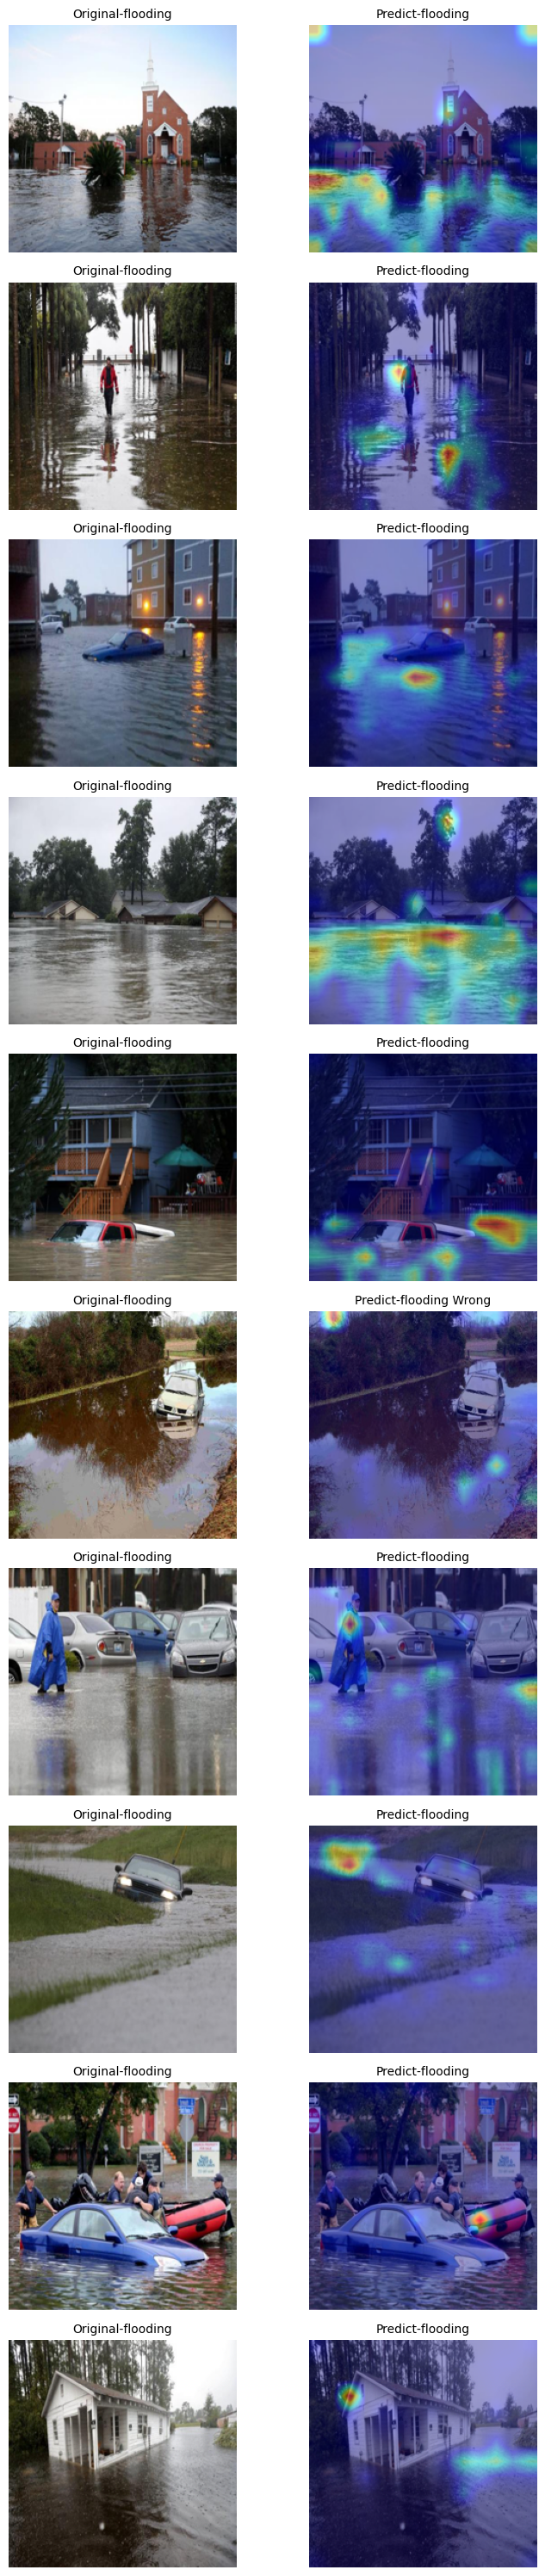

In [ ]:
import os
import random
import torch
import numpy as np
import matplotlib.pyplot as plt
import timm
from torchvision import transforms
from PIL import Image
import cv2

# -------------------------------
# 1. Device
# -------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------------
# 2. Load model
# -------------------------------
num_classes = 2
best_fold = 3
model = timm.create_model('vit_tiny_patch16_224', pretrained=True, num_classes=num_classes)
model.load_state_dict(torch.load(
    f'/content/drive/MyDrive/models/best_vit_fold{best_fold}.pth',
    map_location=device
))
model.to(device)
model.eval()
print(f"✅ Loaded best fold model: Fold {best_fold}")

# -------------------------------
# 3. Transform
# -------------------------------
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])

# -------------------------------
# 4. Grad-CAM Function
# -------------------------------
def gradcam_on_image(img_path):
    img = Image.open(img_path).convert("RGB")
    input_tensor = transform(img).unsqueeze(0).to(device)
    input_tensor.requires_grad = True

    activations, gradients = {}, {}

    def forward_hook(module, inp, out):
        activations["value"] = out.detach()
    def backward_hook(module, grad_in, grad_out):
        gradients["value"] = grad_out[0].detach()

    target_layer = model.blocks[-1].norm1
    #target_layer = model.blocks[-1].attn.proj
    fh = target_layer.register_forward_hook(forward_hook)
    bh = target_layer.register_full_backward_hook(backward_hook)

    output = model(input_tensor)
    pred_class = output.argmax(dim=1).item()

    model.zero_grad()
    output[0, pred_class].backward()

    fh.remove()
    bh.remove()

    act_patches = activations["value"][:, 1:, :]
    grad_patches = gradients["value"][:, 1:, :]
    weights = grad_patches.mean(dim=2, keepdim=True)
    cam = (weights * act_patches).sum(dim=2)

    H_patch = W_patch = int(np.sqrt(cam.shape[1]))
    cam = cam.reshape(H_patch, W_patch)
    cam = torch.relu(cam).cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    cam = cv2.resize(cam, (224,224))

    heatmap = cv2.applyColorMap(np.uint8(255*cam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    orig_img = np.array(img.resize((224,224)))
    cam_img = cv2.addWeighted(orig_img, 0.6, heatmap, 0.4, 0)

    return orig_img, cam_img, pred_class

# -------------------------------
# 5. Show Grad-CAM for Normal class
# -------------------------------
flood_dir = '/content/drive/MyDrive/Flood_data_k_fold/test/flooding'

all_images = os.listdir(flood_dir)
chosen_imgs = random.sample(all_images, min(10, len(all_images)))

# Assuming Normal class index is 0 (adjust according to your model)
flooding_index = 0

samples = []
for img_name in chosen_imgs:
    img_path = os.path.join(flood_dir, img_name)
    orig, cam, pred_class = gradcam_on_image(img_path)
    correct = (pred_class == flooding_index)
    samples.append({"orig": orig, "cam": cam, "correct": correct})

cols = 2
rows = len(samples)
plt.figure(figsize=(8, rows*3))

for i, s in enumerate(samples):
    # Original
    plt.subplot(rows, cols, 2*i+1)
    plt.imshow(s["orig"])
    plt.title("Original-flooding", fontsize=10)
    plt.axis("off")

    # Grad-CAM
    plt.subplot(rows, cols, 2*i+2)
    plt.imshow(s["cam"])
    if s["correct"]:
        plt.title("Predict-flooding", fontsize=10)
    else:
        plt.title("Predict-flooding Wrong", fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()


✅ Loaded best fold model: Fold 3


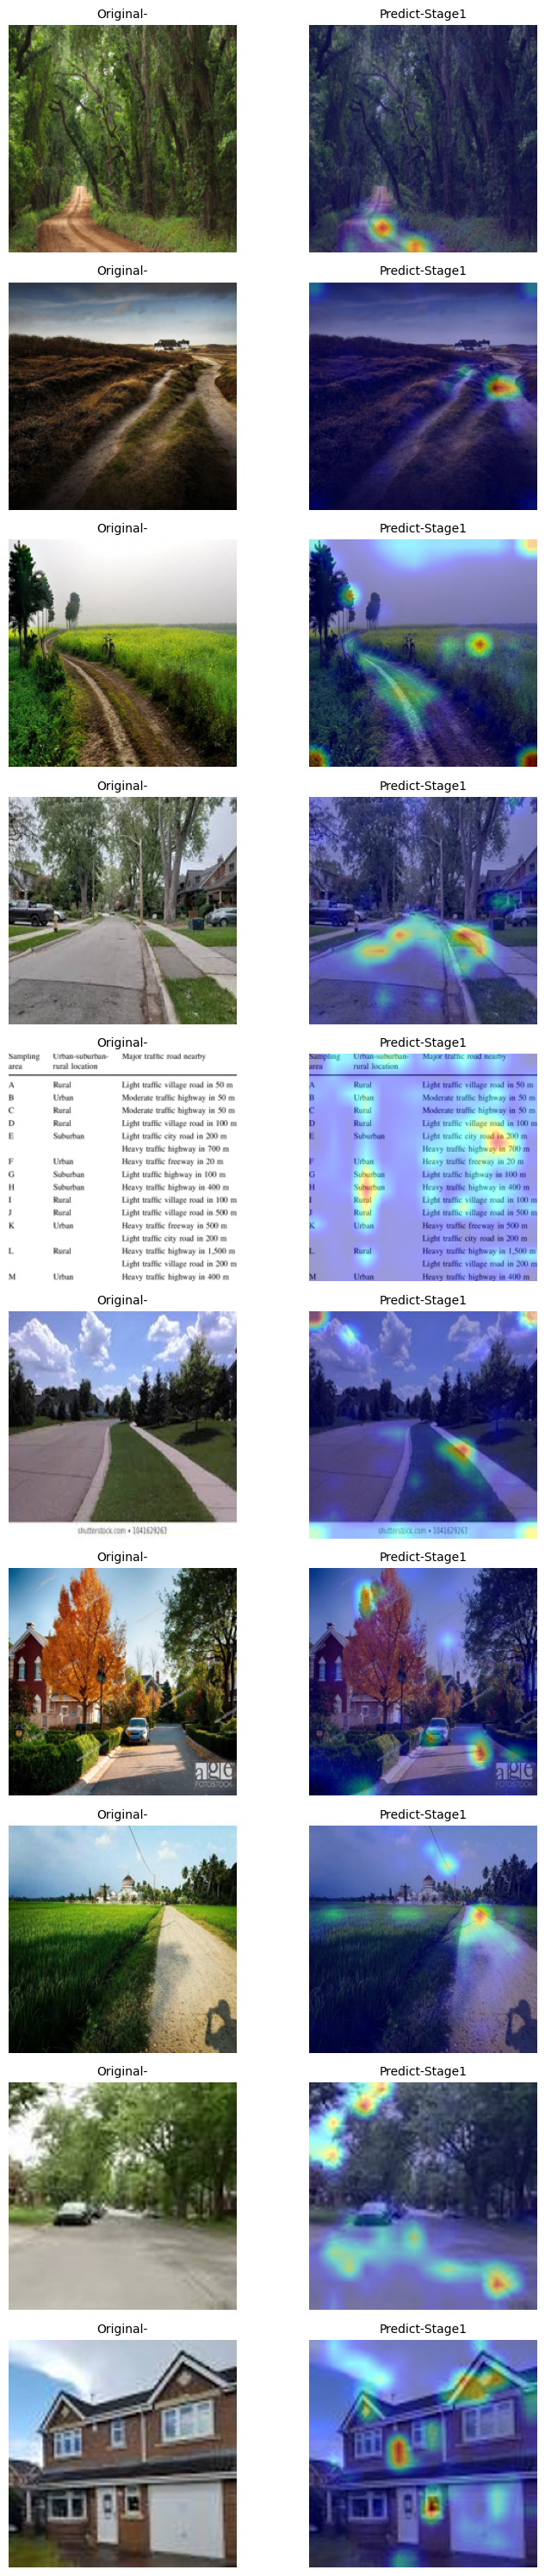

In [ ]:
import os
import random
import torch
import numpy as np
import matplotlib.pyplot as plt
import timm
from torchvision import transforms
from PIL import Image
import cv2

# -------------------------------
# 1. Device
# -------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------------
# 2. Load model
# -------------------------------
num_classes = 2 # Changed from 5 to 2
best_fold = 3
model = timm.create_model('vit_tiny_patch16_224', pretrained=True, num_classes=num_classes)
model.load_state_dict(torch.load(
    f'/content/drive/MyDrive/models/best_vit_fold{best_fold}.pth',
    map_location=device
))
model.to(device)
model.eval()
print(f"✅ Loaded best fold model: Fold {best_fold}")

# -------------------------------
# 3. Transform
# -------------------------------
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])

# -------------------------------
# 4. Grad-CAM Function
# -------------------------------
def gradcam_on_image(img_path):
    img = Image.open(img_path).convert("RGB")
    input_tensor = transform(img).unsqueeze(0).to(device)
    input_tensor.requires_grad = True

    activations, gradients = {}, {}

    def forward_hook(module, inp, out):
        activations["value"] = out.detach()
    def backward_hook(module, grad_in, grad_out):
        gradients["value"] = grad_out[0].detach()

    target_layer = model.blocks[-1].norm1
    #target_layer = model.blocks[-1].attn.proj
    fh = target_layer.register_forward_hook(forward_hook)
    bh = target_layer.register_full_backward_hook(backward_hook)

    output = model(input_tensor)
    pred_class = output.argmax(dim=1).item()

    model.zero_grad()
    output[0, pred_class].backward()

    fh.remove()
    bh.remove()

    act_patches = activations["value"][:, 1:, :]
    grad_patches = gradients["value"][:, 1:, :]
    weights = grad_patches.mean(dim=2, keepdim=True)
    cam = (weights * act_patches).sum(dim=2)

    H_patch = W_patch = int(np.sqrt(cam.shape[1]))
    cam = cam.reshape(H_patch, W_patch)
    cam = torch.relu(cam).cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    cam = cv2.resize(cam, (224,224))

    heatmap = cv2.applyColorMap(np.uint8(255*cam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    orig_img = np.array(img.resize((224,224)))
    cam_img = cv2.addWeighted(orig_img, 0.6, heatmap, 0.4, 0)

    return orig_img, cam_img, pred_class

# -------------------------------
# 5. Show Grad-CAM for Stage1 class
# -------------------------------
# Corrected directory path
normal_dir = '/content/drive/MyDrive/Flood_data_k_fold/test/normal'

all_images = os.listdir(normal_dir)
chosen_imgs = random.sample(all_images, min(10, len(all_images)))


normal_index = 1 # Assuming 'flooding' is the first class (index 0) based on the previous cell

samples = []
for img_name in chosen_imgs:
    img_path = os.path.join(normal_dir, img_name)
    orig, cam, pred_class = gradcam_on_image(img_path)
    correct = (pred_class == normal_index)
    samples.append({"orig": orig, "cam": cam, "correct": correct})

cols = 2
rows = len(samples)
plt.figure(figsize=(8, rows*3))

for i, s in enumerate(samples):
    # Original
    plt.subplot(rows, cols, 2*i+1)
    plt.imshow(s["orig"])
    plt.title(f"Original-{'normal' if normal_index == 0 else ''}", fontsize=10) # Update title
    plt.axis("off")

    # Grad-CAM
    plt.subplot(rows, cols, 2*i+2)
    plt.imshow(s["cam"])
    if s["correct"]:
        plt.title(f"Predict-{'flooding' if normal_index == 0 else 'Stage1'}", fontsize=10) # Update title
    else:
        plt.title(f"Predict-{'flooding' if normal_index == 0 else 'Stage1'} Wrong", fontsize=10) # Update title
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import torch
import numpy as np
import timm
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report

# -------------------------------
# 1. Device
# -------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------------
# 2. Load the best model
# -------------------------------
num_classes = 2 # Make sure this matches the number of classes in your dataset
best_fold = 4  # Or the fold with the best validation accuracy
model = timm.create_model('vit_tiny_patch16_224', pretrained=False, num_classes=num_classes) # pretrained=False as we load saved weights
model.load_state_dict(torch.load(
    f'/content/drive/MyDrive/models/best_vit_fold{best_fold}.pth',
    map_location=device
))
model.to(device)
model.eval()
print(f"✅ Loaded best fold model: Fold {best_fold}")

# -------------------------------
# 3. Load the test dataset
# -------------------------------
test_dir = '/content/drive/MyDrive/Flood_data_k_fold/test' # Replace with your test data path
transform_test = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])
test_dataset = ImageFolder(test_dir, transform=transform_test)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
class_names = test_dataset.classes
print(f"✅ Loaded test dataset with {len(test_dataset)} images and {len(class_names)} classes: {class_names}")


# -------------------------------
# 4. Evaluate the model on the test dataset
# -------------------------------
all_preds, all_targets = [], []
correct, total = 0, 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        preds = outputs.argmax(1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(labels.cpu().numpy())
        correct += (preds == labels).sum().item()
        total += labels.size(0)

test_accuracy = correct / total
print(f"\n📊 Test Accuracy: {test_accuracy:.4f}")

# -------------------------------
# 5. Classification Report for the test dataset
# -------------------------------
print("\n📑 Test Classification Report:")
print(classification_report(all_targets, all_preds, target_names=class_names, digits=4))

✅ Loaded best fold model: Fold 4
✅ Loaded test dataset with 71 images and 2 classes: ['flooding', 'normal']

📊 Test Accuracy: 0.9437

📑 Test Classification Report:
              precision    recall  f1-score   support

    flooding     1.0000    0.9070    0.9512        43
      normal     0.8750    1.0000    0.9333        28

    accuracy                         0.9437        71
   macro avg     0.9375    0.9535    0.9423        71
weighted avg     0.9507    0.9437    0.9442        71



In [ ]:
print(model)


VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 192, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((192,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=192, out_features=576, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (proj): Linear(in_features=192, out_features=192, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): Identity()
      (drop_path1): Identity()
      (norm2): LayerNorm((192,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=192, out_features=768, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(p=0.0, inplace=False)


✅ Loaded best fold model: Fold 4


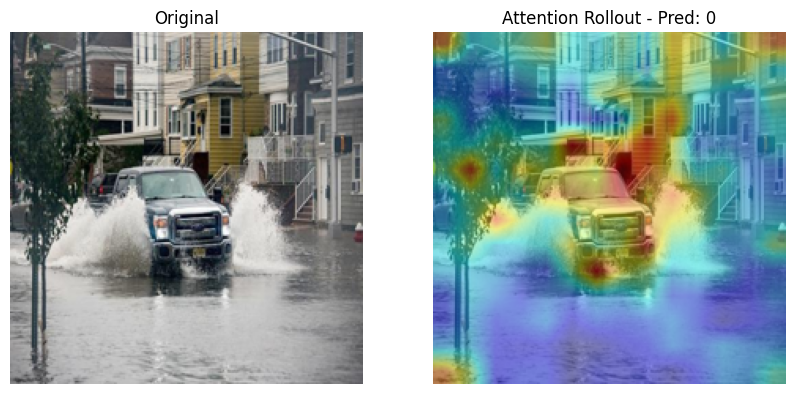

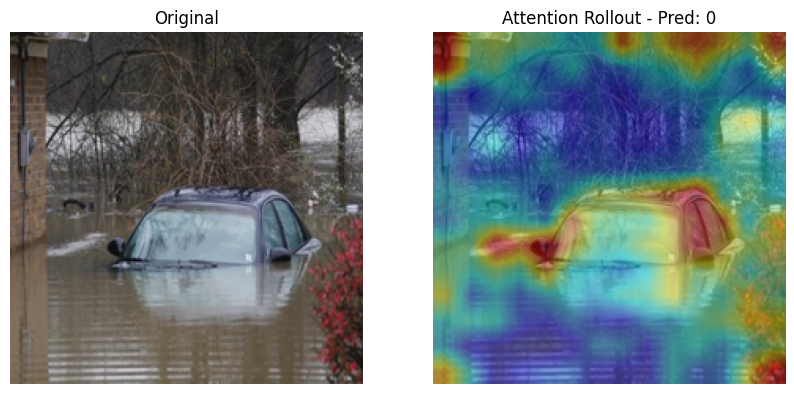

In [ ]:
import torch
import torch.nn.functional as F
import timm
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image
import math

# ----------------------------
# 1. Load Model
# ----------------------------
num_classes=2
best_fold = 4  # Or the fold with the best validation accuracy
model = timm.create_model('vit_tiny_patch16_224', pretrained=False, num_classes=num_classes) # pretrained=False as we load saved weights
model.load_state_dict(torch.load(
    f'/content/drive/MyDrive/models/best_vit_fold{best_fold}.pth',
    map_location=device
))
model.to(device)
model.eval()
print(f"✅ Loaded best fold model: Fold {best_fold}")

# ----------------------------
# 2. Image Transform
# ----------------------------
from torchvision import transforms
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225]),
])

# ----------------------------
# 3. Attention Rollout Function
# ----------------------------
def attention_rollout_on_image(img_path, return_cls_pred=True):
    img = Image.open(img_path).convert("RGB")
    input_tensor = transform(img).unsqueeze(0).to(device)  # (1,3,224,224)

    qkv_outputs = []

    # Hook to capture qkv output
    def make_hook():
        def hook(module, inp, out):
            qkv_outputs.append(out.detach().cpu())
        return hook

    hooks = []
    for blk in model.blocks:
        if hasattr(blk.attn, "qkv"):
            hooks.append(blk.attn.qkv.register_forward_hook(make_hook()))
        else:
            hooks.append(blk.attn.register_forward_hook(make_hook()))

    # Forward pass
    with torch.no_grad():
        output = model(input_tensor)

    # Remove hooks
    for h in hooks:
        h.remove()

    pred_class = int(output.argmax(dim=1).item()) if return_cls_pred else None

    attn_matrices = []
    for qkv in qkv_outputs:
        B, N, threeE = qkv.shape
        embed_dim = threeE // 3

        try:
            n_heads = model.blocks[0].attn.num_heads
        except Exception:
            possible = [12, 6, 3, 2, 1]
            n_heads = next((h for h in possible if embed_dim % h == 0), 1)

        head_dim = embed_dim // n_heads

        qkv_reshape = qkv.reshape(B, N, 3, n_heads, head_dim)
        qkv_perm = qkv_reshape.permute(2, 0, 3, 1, 4).numpy()
        q = torch.from_numpy(qkv_perm[0]).to(device)
        k = torch.from_numpy(qkv_perm[1]).to(device)

        scale = 1.0 / math.sqrt(head_dim)
        attn = torch.matmul(q, k.transpose(-2, -1)) * scale
        attn = F.softmax(attn, dim=-1)

        attn_avg = attn.mean(dim=1).detach().cpu()
        attn_matrices.append(attn_avg)

    # Rollout with residuals
    result = torch.eye(attn_matrices[0].size(-1))
    for attn in attn_matrices:
        a = attn[0]
        a = a + torch.eye(a.size(0))
        a = a / a.sum(dim=-1, keepdim=True)
        result = torch.matmul(a, result)

    cls_attn = result[0, 1:]
    n_patches = cls_attn.shape[0]
    H_patch = W_patch = int(np.sqrt(n_patches))
    mask = cls_attn.reshape(H_patch, W_patch).numpy()
    mask = (mask - mask.min()) / (mask.max() - mask.min() + 1e-8)
    mask = cv2.resize(mask, (224, 224))

    heatmap = cv2.applyColorMap(np.uint8(255 * mask), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    orig_img = np.array(img.resize((224, 224)))
    cam_img = cv2.addWeighted(orig_img, 0.6, heatmap, 0.4, 0)

    return orig_img, cam_img, pred_class

# ----------------------------
# 4. Example Usage
# ----------------------------
# Replace with your dataset paths
img_paths = [
    "/content/drive/MyDrive/Flood_data_k_fold/test/flooding/image_226.jpg",
    "/content/drive/MyDrive/Flood_data_k_fold/test/flooding/image_225.jpg"
]

for path in img_paths:
    orig, cam, pred = attention_rollout_on_image(path)
    plt.figure(figsize=(10,5))
    plt.subplot(1,2,1)
    plt.imshow(orig)
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(cam)
    plt.title(f"Attention Rollout - Pred: {pred}")
    plt.axis("off")
    plt.show()


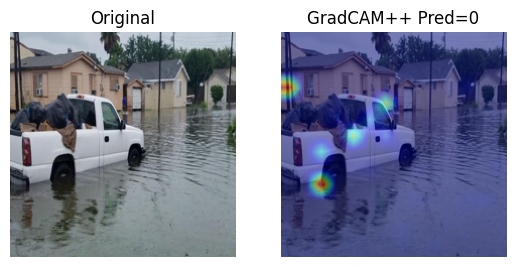

In [ ]:
import torch
import timm
import numpy as np
import cv2
import matplotlib.pyplot as plt
from torchvision import transforms
from PIL import Image
import os

# -------------------------------
# 1. Setup
# -------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Define the same normalization used during training
val_tfms = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225])
])

# -------------------------------
# 2. Load Model & Weights
# -------------------------------
num_classes = 2  # flooding / normal
model = timm.create_model("vit_tiny_patch16_224", pretrained=False, num_classes=num_classes)
model.to(device)

# Load your saved checkpoint from Google Drive
checkpoint_path = "/content/drive/MyDrive/models/best_vit_fold3.pth"  # change if needed
model.load_state_dict(torch.load(checkpoint_path, map_location=device))
model.eval()

# -------------------------------
# 3. Grad-CAM++ Implementation
# -------------------------------
def gradcam_plus(img_path):
    img = Image.open(img_path).convert("RGB")
    input_tensor = val_tfms(img).unsqueeze(0).to(device)

    activations, gradients = {}, {}

    def forward_hook(module, inp, out):
        activations["value"] = out
    def backward_hook(module, grad_in, grad_out):
        gradients["value"] = grad_out[0]

    # hook into last transformer block's norm layer
    layer = model.blocks[-1].norm1
    fh = layer.register_forward_hook(forward_hook)
    bh = layer.register_full_backward_hook(backward_hook)

    out = model(input_tensor)
    pred_class = out.argmax(1).item()

    model.zero_grad()
    out[0, pred_class].backward()

    fh.remove()
    bh.remove()

    A = activations["value"][:,1:,:]   # remove CLS token
    G = gradients["value"][:,1:,:]

    weights = (G**2).sum(dim=2, keepdim=True) / (2*G**2 + (A*G**3).sum(dim=2, keepdim=True)+1e-8)
    cam = (weights * A).sum(dim=2)
    cam = cam.reshape(int(np.sqrt(cam.shape[1])), -1).detach().cpu().numpy()
    cam = np.maximum(cam,0)
    cam = (cam-cam.min())/(cam.max()-cam.min()+1e-8)
    cam = cv2.resize(cam, (224,224))

    heatmap = cv2.applyColorMap(np.uint8(255*cam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    orig = np.array(img.resize((224,224)))
    overlay = cv2.addWeighted(orig, 0.6, heatmap, 0.4, 0)

    return orig, overlay, pred_class

# -------------------------------
# 4. Test on One Image
# -------------------------------
test_img = "/content/drive/MyDrive/data/test/flooding/image_224.jpg"  # change path
orig, overlay, pred = gradcam_plus(test_img)

plt.subplot(1,2,1); plt.imshow(orig); plt.title("Original"); plt.axis("off")
plt.subplot(1,2,2); plt.imshow(overlay); plt.title(f"GradCAM++ Pred={pred}"); plt.axis("off")
plt.show()
